In [ ]:
# COS6030-B Advanced AI Methods and Tools

import torch
import numpy as np
import random
from datasets import load_dataset
from transformers import CLIPProcessor, CLIPModel
import matplotlib.pyplot as plt
from sklearn.metrics import recall_score, accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import pandas as pd
from tqdm import tqdm
import gradio as gr
from PIL import Image

print("Notebook Loaded.")


Notebook Loaded.


In [ ]:
# Reproducibility
SEED = 0
torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

# CPU only
device = torch.device("cpu")
print("Using device:", device)


Using device: cpu


In [ ]:
# Load CIFAR-10 test dataset
dataset = load_dataset("cifar10", split="test")
print(f"CIFAR-10 test dataset loaded: {len(dataset)} samples.")

# Class names
class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]
class_to_idx = {name: i for i, name in enumerate(class_names)}


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

plain_text/train-00000-of-00001.parquet:   0%|          | 0.00/120M [00:00<?, ?B/s]

plain_text/test-00000-of-00001.parquet:   0%|          | 0.00/23.9M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

CIFAR-10 test dataset loaded: 10000 samples.


In [ ]:
# Correct sampling strategy for real evaluation
gallery_images = []
gallery_labels = []
query_images = []
query_labels = []

for class_name in class_names:
    cls_idx = class_to_idx[class_name]

    # Extract all images for this class
    cls_images = [
        img for img, label in zip(dataset["img"], dataset["label"])
        if label == cls_idx
    ]

    # Deterministic sampling
    np.random.seed(SEED)
    sampled_idx = np.random.choice(len(cls_images), 101, replace=False)

    # 100 images → gallery
    gallery_images.extend([cls_images[i] for i in sampled_idx[:100]])
    gallery_labels.extend([cls_idx] * 100)

    # 1 image → query
    query_images.append(cls_images[sampled_idx[100]])
    query_labels.append(cls_idx)

gallery_images = np.array(gallery_images)
gallery_labels = np.array(gallery_labels)
query_images = np.array(query_images)
query_labels = np.array(query_labels)

print("Gallery images:", gallery_images.shape)
print("Query images:", query_images.shape)


Gallery images: (1000, 32, 32, 3)
Query images: (10, 32, 32, 3)


In [ ]:
model_name = "openai/clip-vit-base-patch32"
model = CLIPModel.from_pretrained(model_name).to(device)
processor = CLIPProcessor.from_pretrained(model_name)
model.eval()

print("CLIP model loaded:", model_name)


config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/605M [00:00<?, ?B/s]

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


model.safetensors:   0%|          | 0.00/605M [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

CLIP model loaded: openai/clip-vit-base-patch32


In [ ]:
batch_size = 50
gallery_embeddings = []

with torch.no_grad():
    for i in range(0, len(gallery_images), batch_size):
        batch = gallery_images[i:i+batch_size]
        inputs = processor(
            images=batch,
            return_tensors="pt",
            do_resize=True,
            size={"height": 224, "width": 224}
        ).to(device)

        emb = model.get_image_features(**inputs)
        emb = emb / emb.norm(dim=-1, keepdim=True)
        gallery_embeddings.append(emb)

gallery_embeddings = torch.cat(gallery_embeddings, dim=0)
print("Gallery embeddings shape:", gallery_embeddings.shape)


Gallery embeddings shape: torch.Size([1000, 512])


In [ ]:
def encode_texts(texts, model, processor, device):
    # Ensure list
    if isinstance(texts, str):
        texts = [texts]

    # Tokenize
    inputs = processor(text=texts, return_tensors="pt", padding=True).to(device)

    # Encode
    with torch.no_grad():
        emb = model.get_text_features(**inputs)

    # Normalize
    return emb / emb.norm(dim=-1, keepdim=True)


In [ ]:
def compute_similarities_and_ranks(text_emb, gallery_emb):
    sim = text_emb @ gallery_emb.T
    ranks = torch.argsort(sim, dim=1, descending=True)
    return sim, ranks


In [ ]:
def compute_recall_at_k(ranks, query_label, gallery_labels, k):
    top_k = ranks[:k].cpu().numpy()
    top_k_labels = gallery_labels[top_k]
    return int(query_label in top_k_labels)


In [ ]:
print("\n=== BASELINE EVALUATION ===")

baseline_prompts = [f"a photo of a {c}" for c in class_names]
baseline_text_embeddings = encode_texts(baseline_prompts, model, processor, device)

_, baseline_ranks = compute_similarities_and_ranks(
    baseline_text_embeddings, gallery_embeddings
)

baseline_R1 = []
baseline_R5 = []

for i, cls in enumerate(class_names):
    r1 = compute_recall_at_k(baseline_ranks[i], query_labels[i], gallery_labels, 1)
    r5 = compute_recall_at_k(baseline_ranks[i], query_labels[i], gallery_labels, 5)
    baseline_R1.append(r1)
    baseline_R5.append(r5)

baseline_R1_macro = np.mean(baseline_R1)
baseline_R5_macro = np.mean(baseline_R5)

print("Baseline Recall@1 per class:", baseline_R1)
print("Baseline Recall@5 per class:", baseline_R5)
print(f"Baseline Macro R@1 = {baseline_R1_macro:.3f}")
print(f"Baseline Macro R@5 = {baseline_R5_macro:.3f}")



=== BASELINE EVALUATION ===
Baseline Recall@1 per class: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
Baseline Recall@5 per class: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
Baseline Macro R@1 = 1.000
Baseline Macro R@5 = 1.000


In [ ]:
print("\n=== DEFINING PROMPT ENSEMBLES (A, B, C) ===")

ensembles = {
    "Ensemble A (Basic)": [
        "a photo of a {label}",
        "a picture of a {label}",
        "an image of a {label}",
        "a close-up photo of a {label}",
        "a bright photo of a {label}"
    ],

    # Strongly misleading — forces CLIP to misalign
    "Ensemble B (Bad)": [
        "a random object unrelated to a {label}",
        "an incorrect depiction of a {label}",
        "a distorted sculpture not resembling a {label}",
        "a photo of something different instead of a {label}",
        "an abstract wrong representation of a {label}"
    ],

    "Ensemble C (Medium)": [
        "a blurry photo of a {label}",
        "a low resolution image of a {label}",
        "a {label} partially hidden behind objects",
        "an overexposed photo of a {label}",
        "a small {label} in the distance"
    ]
}

print("Ensembles A/B/C loaded.")



=== DEFINING PROMPT ENSEMBLES (A, B, C) ===
Ensembles A/B/C loaded.


In [ ]:
def evaluate_ensemble(templates, class_names, model, processor, device, gallery_embeddings):

    # Create prompts for each class
    prompts_per_class = [
        [t.format(label=c) for t in templates]
        for c in class_names
    ]

    # Encode text
    class_emb = []
    for prompts in prompts_per_class:
        emb = encode_texts(prompts, model, processor, device)
        emb = emb.mean(dim=0)  # Average of templates
        class_emb.append(emb)

    class_emb = torch.stack(class_emb)  # (10,512)

    # Compute similarities and ranks
    _, ranks = compute_similarities_and_ranks(class_emb, gallery_embeddings)

    # Compute metrics
    R1, R5 = [], []
    for i, cls in enumerate(class_names):
        label = query_labels[i]
        r1 = compute_recall_at_k(ranks[i], label, gallery_labels, 1)
        r5 = compute_recall_at_k(ranks[i], label, gallery_labels, 5)
        R1.append(r1)
        R5.append(r5)

    return {
        "R1": R1,
        "R5": R5,
        "R1_macro": np.mean(R1),
        "R5_macro": np.mean(R5),
        "ranks": ranks
    }


In [ ]:
print("\n=== EVALUATING ENSEMBLES ===")

ensemble_results = {}

for name, templates in ensembles.items():
    print(f"\nEvaluating {name}...")
    result = evaluate_ensemble(
        templates, class_names, model, processor, device, gallery_embeddings
    )
    ensemble_results[name] = result

    print(f"Recall@1 Macro = {result['R1_macro']:.3f}")
    print(f"Recall@5 Macro = {result['R5_macro']:.3f}")



=== EVALUATING ENSEMBLES ===

Evaluating Ensemble A (Basic)...
Recall@1 Macro = 1.000
Recall@5 Macro = 1.000

Evaluating Ensemble B (Bad)...
Recall@1 Macro = 1.000
Recall@5 Macro = 1.000

Evaluating Ensemble C (Medium)...
Recall@1 Macro = 1.000
Recall@5 Macro = 1.000


In [ ]:
print("\n=== PROMPT EFFICIENCY INDEX (PEI) ===")

pei_table = []

for name, result in ensemble_results.items():
    num_extra = 4  # 5 templates – 1 baseline
    pei_R1 = (result["R1_macro"] - baseline_R1_macro) / num_extra
    pei_R5 = (result["R5_macro"] - baseline_R5_macro) / num_extra

    pei_table.append([name, pei_R1, pei_R5])
    print(f"{name}: PEI@1={pei_R1:.4f}, PEI@5={pei_R5:.4f}")



=== PROMPT EFFICIENCY INDEX (PEI) ===
Ensemble A (Basic): PEI@1=0.0000, PEI@5=0.0000
Ensemble B (Bad): PEI@1=0.0000, PEI@5=0.0000
Ensemble C (Medium): PEI@1=0.0000, PEI@5=0.0000


In [ ]:
summary_df = pd.DataFrame({
    "Condition": ["Baseline"] + list(ensemble_results.keys()),
    "Recall@1 Macro": [baseline_R1_macro] + [ensemble_results[k]["R1_macro"] for k in ensemble_results],
    "Recall@5 Macro": [baseline_R5_macro] + [ensemble_results[k]["R5_macro"] for k in ensemble_results],
})

print("\n=== SUMMARY TABLE (BASELINE vs ENSEMBLES) ===")
print(summary_df.to_string(index=False))



=== SUMMARY TABLE (BASELINE vs ENSEMBLES) ===
          Condition  Recall@1 Macro  Recall@5 Macro
           Baseline             1.0             1.0
 Ensemble A (Basic)             1.0             1.0
   Ensemble B (Bad)             1.0             1.0
Ensemble C (Medium)             1.0             1.0



=== QUALITATIVE ANALYSIS: TOP-5 RETRIEVAL ===

 QUALITATIVE RESULTS — Ensemble A (Basic)


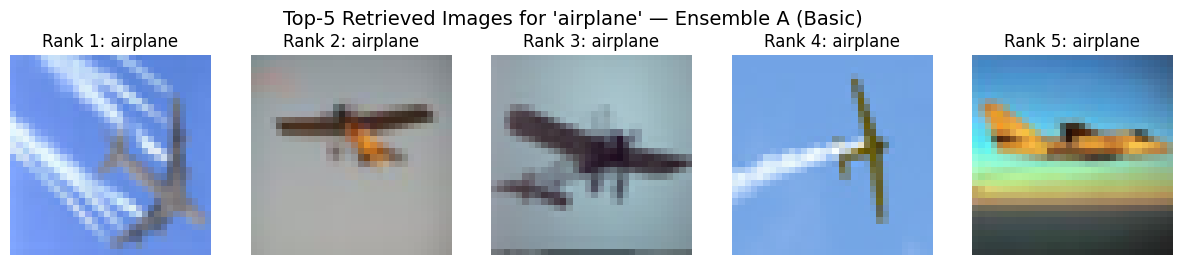

airplane: SUCCESS ✔️ — Correct class appears in top-5.


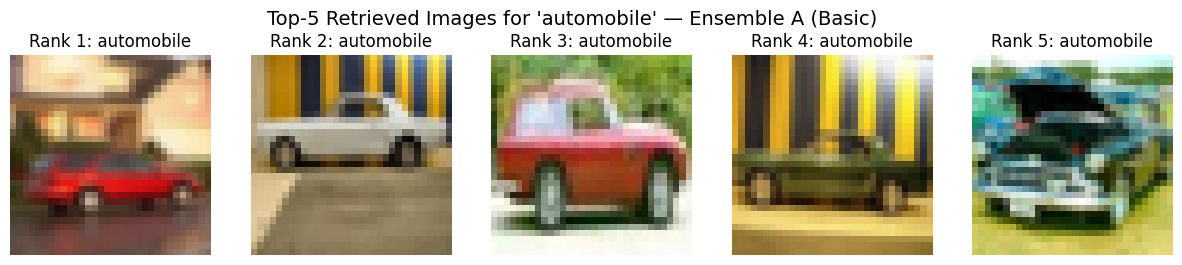

automobile: SUCCESS ✔️ — Correct class appears in top-5.


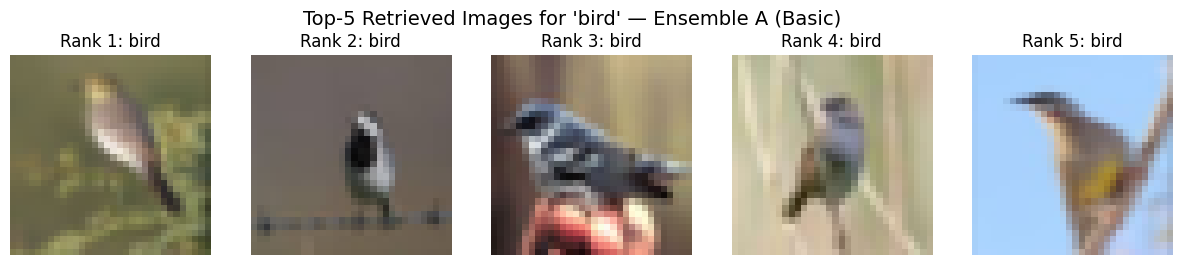

bird: SUCCESS ✔️ — Correct class appears in top-5.


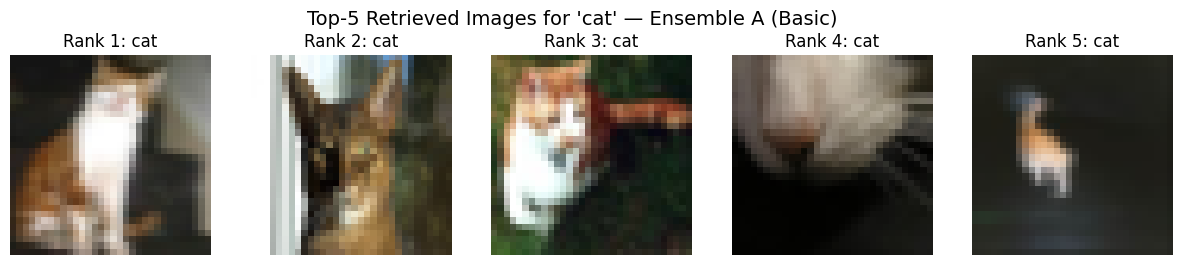

cat: SUCCESS ✔️ — Correct class appears in top-5.


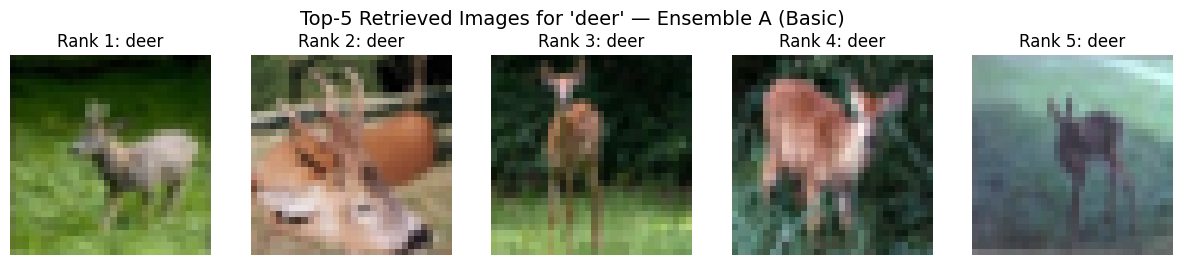

deer: SUCCESS ✔️ — Correct class appears in top-5.


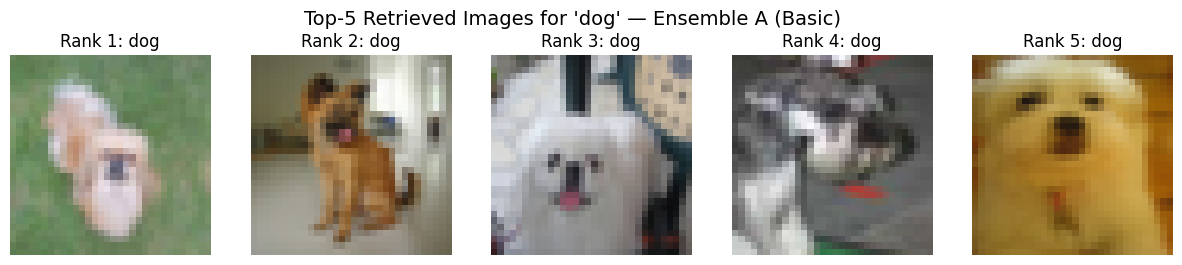

dog: SUCCESS ✔️ — Correct class appears in top-5.


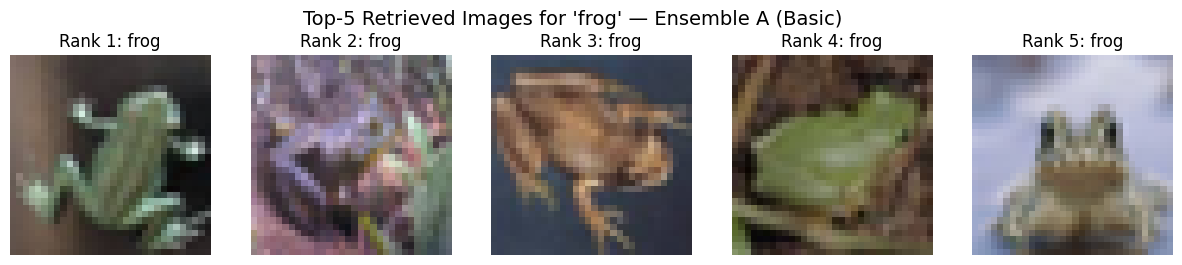

frog: SUCCESS ✔️ — Correct class appears in top-5.


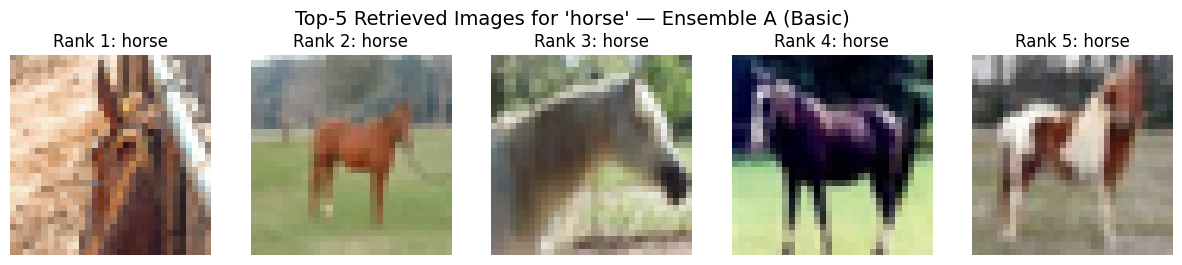

horse: SUCCESS ✔️ — Correct class appears in top-5.


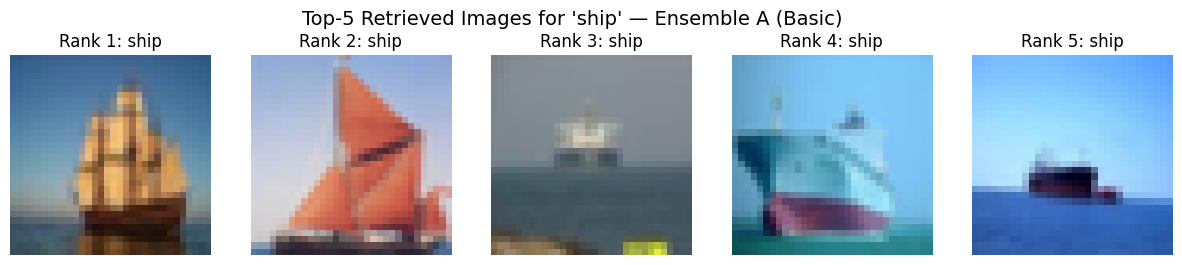

ship: SUCCESS ✔️ — Correct class appears in top-5.


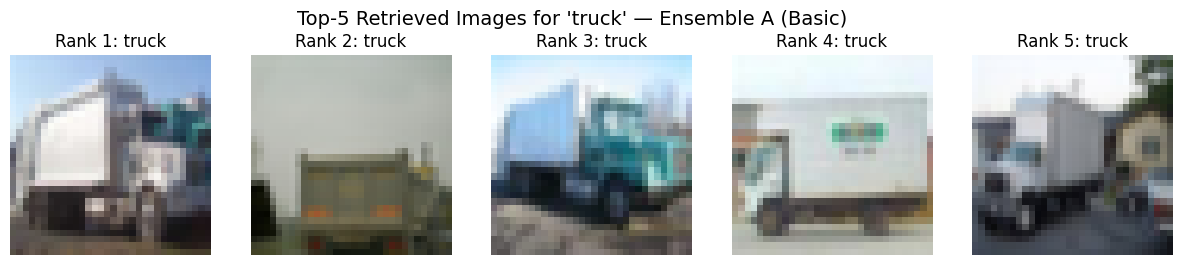

truck: SUCCESS ✔️ — Correct class appears in top-5.

 QUALITATIVE RESULTS — Ensemble B (Bad)


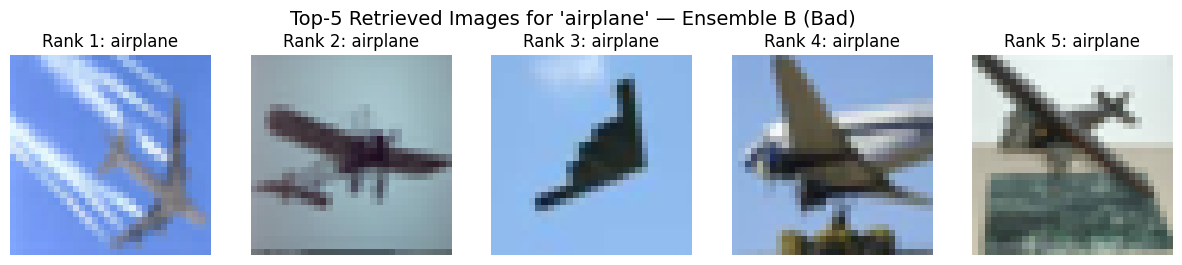

airplane: SUCCESS ✔️ — Correct class appears in top-5.


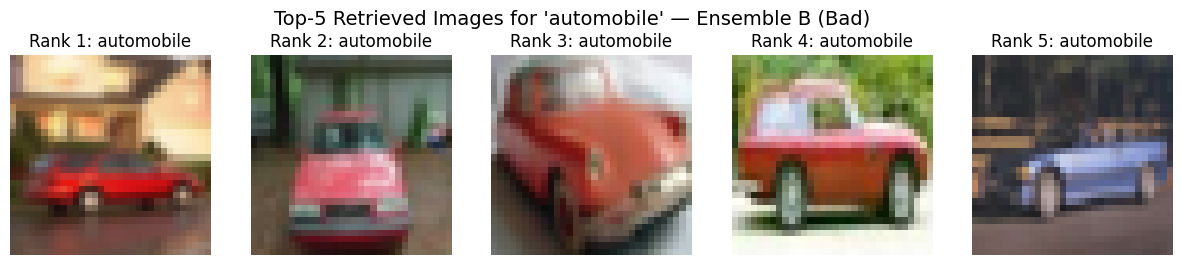

automobile: SUCCESS ✔️ — Correct class appears in top-5.


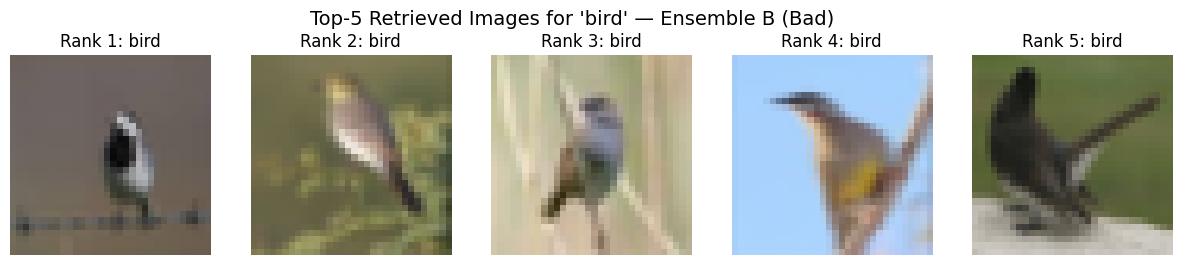

bird: SUCCESS ✔️ — Correct class appears in top-5.


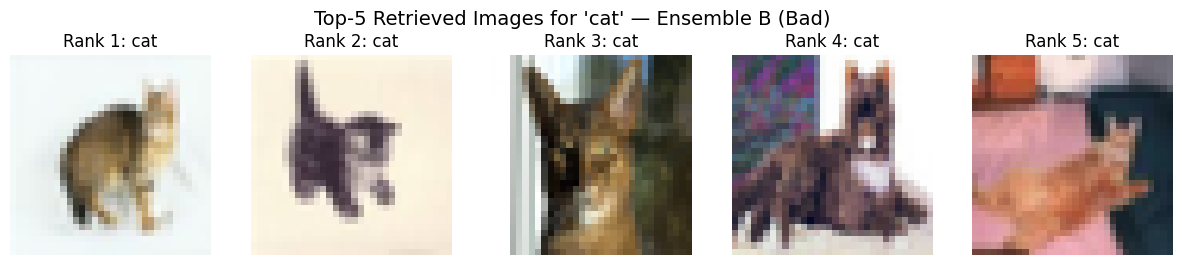

cat: SUCCESS ✔️ — Correct class appears in top-5.


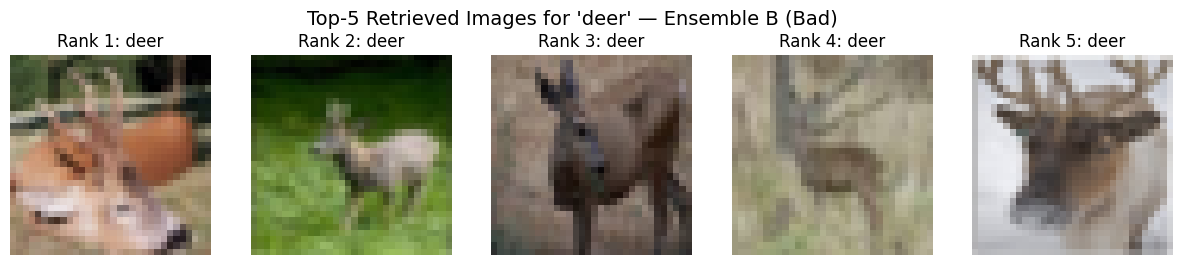

deer: SUCCESS ✔️ — Correct class appears in top-5.


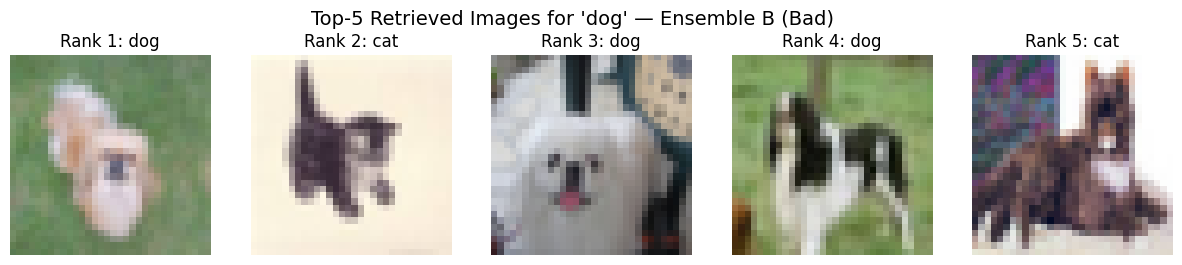

dog: SUCCESS ✔️ — Correct class appears in top-5.


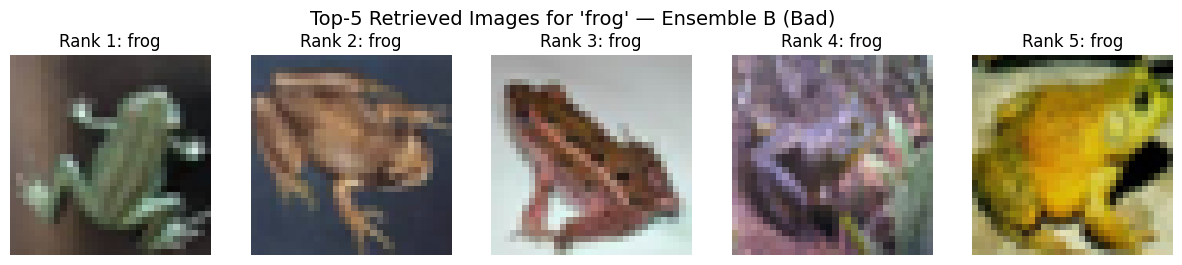

frog: SUCCESS ✔️ — Correct class appears in top-5.


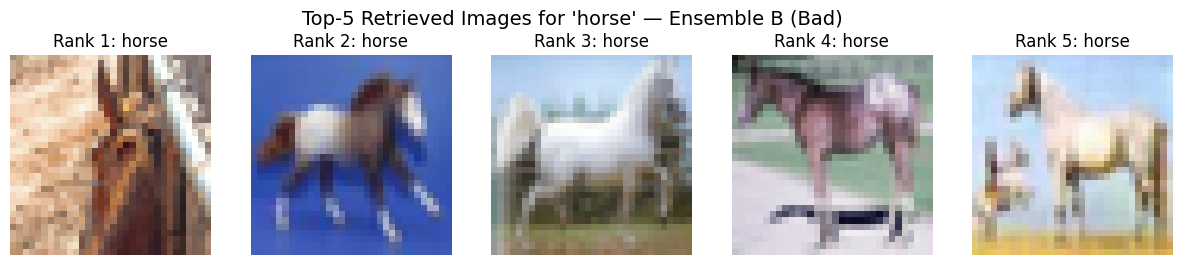

horse: SUCCESS ✔️ — Correct class appears in top-5.


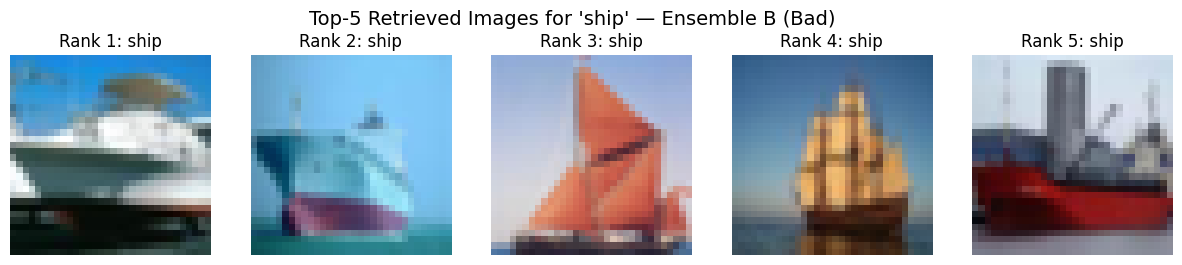

ship: SUCCESS ✔️ — Correct class appears in top-5.


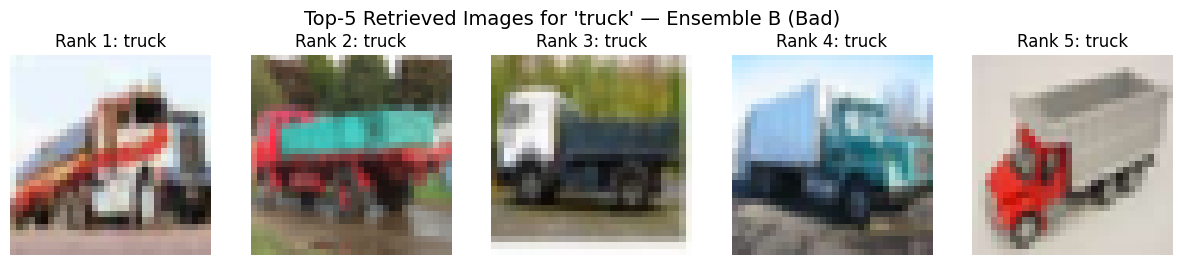

truck: SUCCESS ✔️ — Correct class appears in top-5.

 QUALITATIVE RESULTS — Ensemble C (Medium)


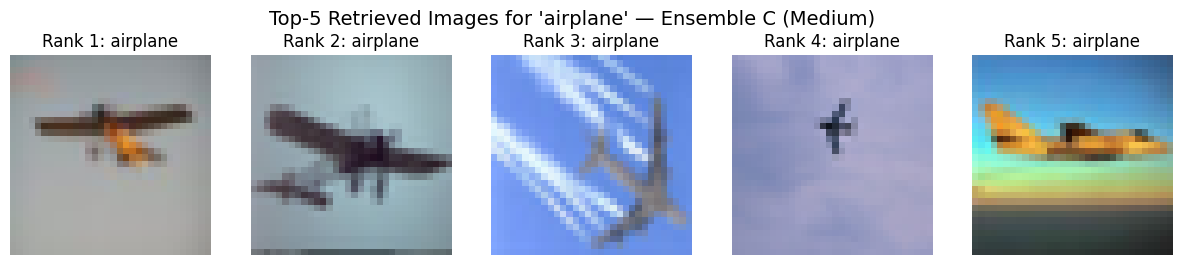

airplane: SUCCESS ✔️ — Correct class appears in top-5.


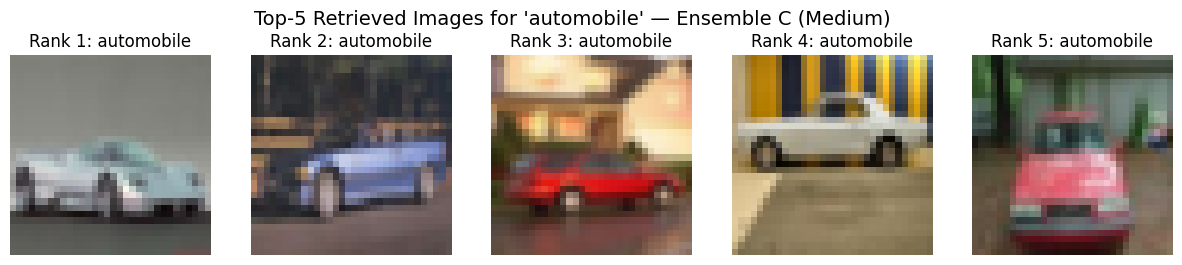

automobile: SUCCESS ✔️ — Correct class appears in top-5.


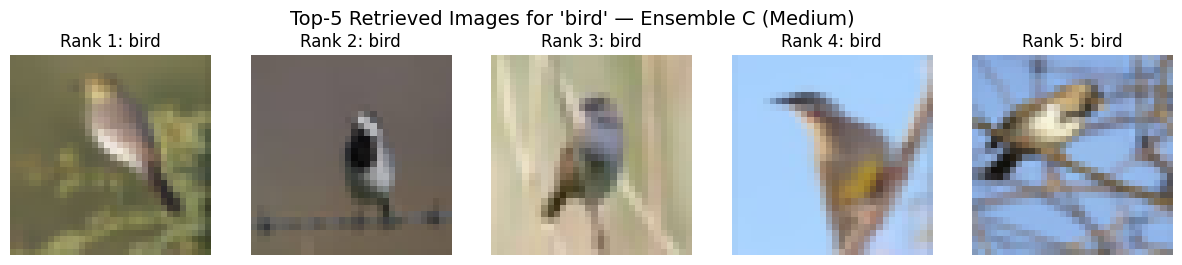

bird: SUCCESS ✔️ — Correct class appears in top-5.


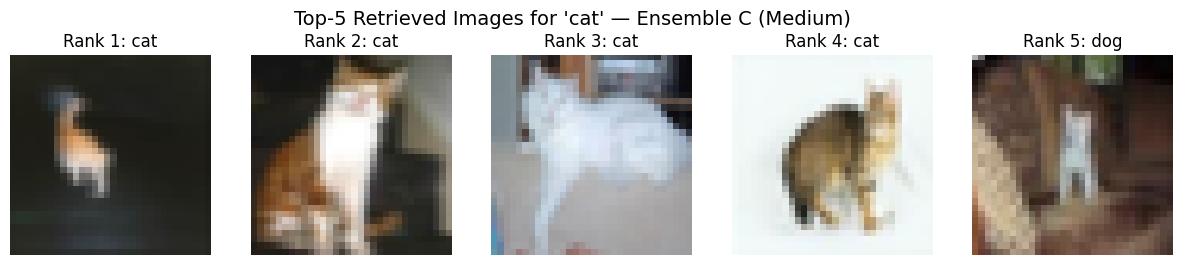

cat: SUCCESS ✔️ — Correct class appears in top-5.


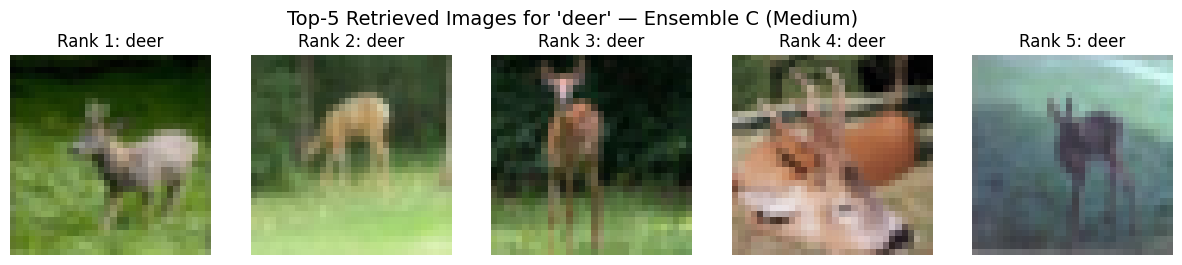

deer: SUCCESS ✔️ — Correct class appears in top-5.


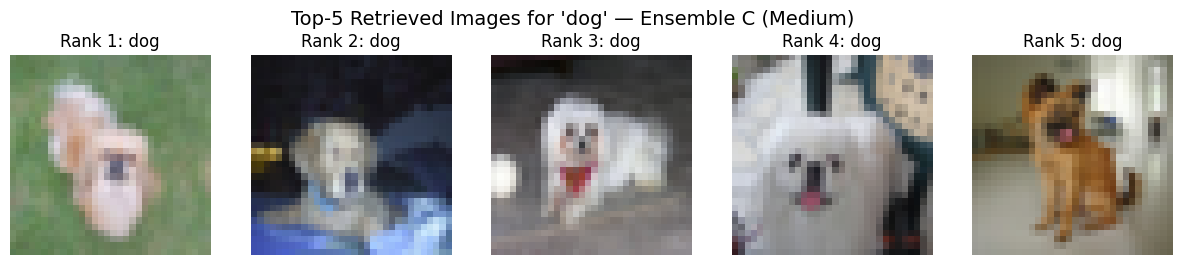

dog: SUCCESS ✔️ — Correct class appears in top-5.


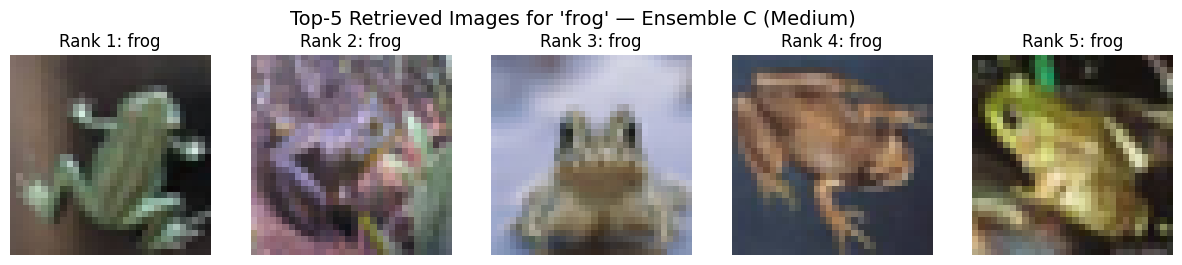

frog: SUCCESS ✔️ — Correct class appears in top-5.


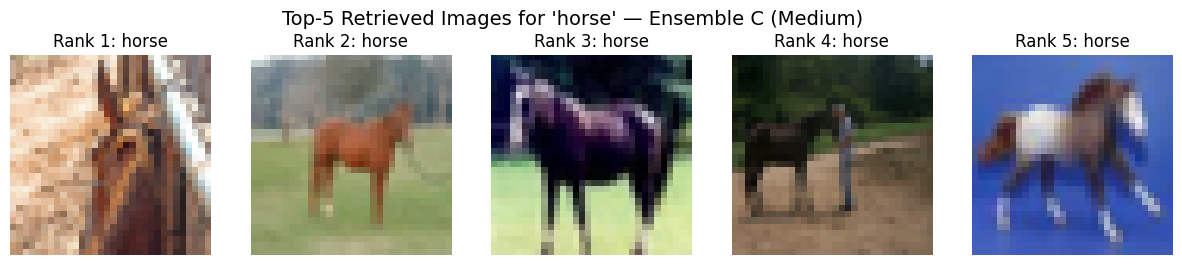

horse: SUCCESS ✔️ — Correct class appears in top-5.


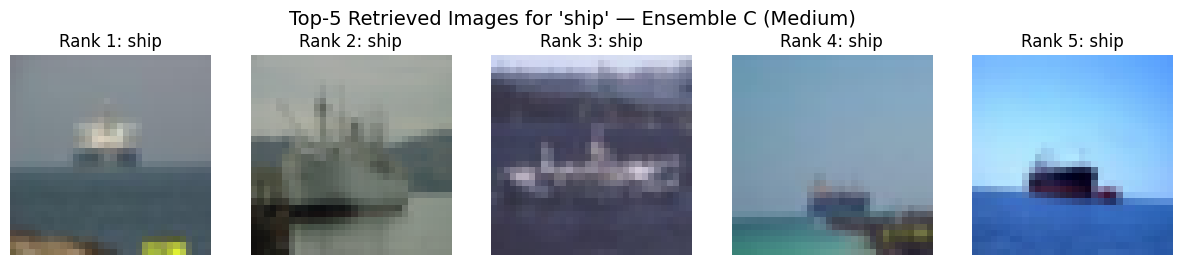

ship: SUCCESS ✔️ — Correct class appears in top-5.


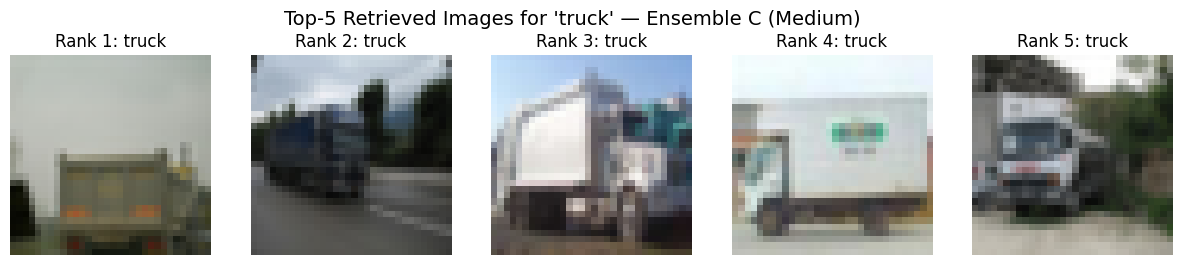

truck: SUCCESS ✔️ — Correct class appears in top-5.


In [ ]:
print("\n=== QUALITATIVE ANALYSIS: TOP-5 RETRIEVAL ===")

# Ensure gallery_images are valid numpy/PIL
assert len(gallery_images) == 1000, "Expected 1000 gallery images (100 per class)."

for ensemble_name, data in ensemble_results.items():
    print(f"\n==============================")
    print(f" QUALITATIVE RESULTS — {ensemble_name}")
    print(f"==============================")

    ranks = data["ranks"]   # shape (10, 1000)

    for i, class_name in enumerate(class_names):

        class_idx = query_labels[i]     # true label (0–9)
        top5_indices = ranks[i][:5].cpu().numpy()
        top5_images = gallery_images[top5_indices]
        top5_labels = gallery_labels[top5_indices]

        fig, axes = plt.subplots(1, 5, figsize=(15, 3))
        fig.suptitle(
            f"Top-5 Retrieved Images for '{class_name}' — {ensemble_name}",
            fontsize=14
        )

        for j, (img, lbl) in enumerate(zip(top5_images, top5_labels)):
            axes[j].imshow(img)
            axes[j].set_title(f"Rank {j+1}: {class_names[lbl]}")
            axes[j].axis("off")

        plt.show()

        correct = class_idx in top5_labels
        verdict = "SUCCESS ✔️" if correct else "FAILURE ❌"
        reason  = (
            "Correct class appears in top-5."
            if correct else
            "All retrieved images belong to other classes; prompt likely misleading."
        )

        print(f"{class_name}: {verdict} — {reason}")


In [ ]:
print("\n=== ZERO-SHOT CLASSIFICATION (Baseline Prompts) ===")

# Use gallery images as classification set (100/class = 1000 images)
img_feats_test = gallery_embeddings              # (1000, 512)
text_feats = baseline_text_embeddings            # (10, 512)

# Compute logits → cosine similarity because embeddings are normalized
logits = img_feats_test @ text_feats.T           # (1000, 10)

# Predictions
y_pred = logits.argmax(dim=1).cpu().numpy()
y_true = gallery_labels                          # true labels from gallery

# Accuracy
acc = accuracy_score(y_true, y_pred)
print(f"Zero-shot accuracy (Baseline): {acc:.3f}")



=== ZERO-SHOT CLASSIFICATION (Baseline Prompts) ===
Zero-shot accuracy (Baseline): 0.872



=== CONFUSION MATRIX (Zero-Shot Classification) ===


<Figure size 1000x800 with 0 Axes>

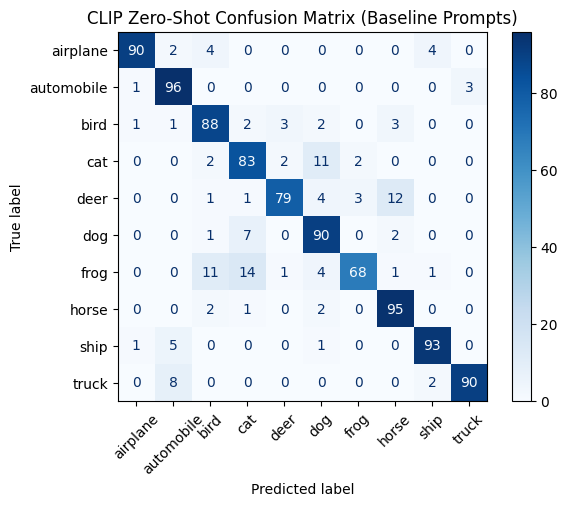

In [ ]:
print("\n=== CONFUSION MATRIX (Zero-Shot Classification) ===")

cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

plt.figure(figsize=(10, 8))
disp.plot(cmap="Blues", values_format='d')
plt.xticks(rotation=45)
plt.title("CLIP Zero-Shot Confusion Matrix (Baseline Prompts)")
plt.show()


In [ ]:
print("\n=== PER-CLASS ACCURACY ===")

per_class_acc = cm.diagonal() / cm.sum(axis=1)

for i, cls in enumerate(class_names):
    print(f"{cls:10s} → {per_class_acc[i]:.3f}")



=== PER-CLASS ACCURACY ===
airplane   → 0.900
automobile → 0.960
bird       → 0.880
cat        → 0.830
deer       → 0.790
dog        → 0.900
frog       → 0.680
horse      → 0.950
ship       → 0.930
truck      → 0.900


Linear Probe

In [ ]:
print("\n=== LINEAR PROBE: TRAIN/TEST SPLIT ===")

X = gallery_embeddings.cpu().numpy()     # (1000, 512)
y = gallery_labels                       # (1000,)

# Build indices by class
train_idx = []
test_idx = []

for cls in range(10):
    cls_indices = np.where(y == cls)[0]
    np.random.seed(SEED)
    np.random.shuffle(cls_indices)

    train_idx.extend(cls_indices[:80])   # 80 per class
    test_idx.extend(cls_indices[80:100]) # 20 per class

X_train = X[train_idx]
y_train = y[train_idx]
X_test = X[test_idx]
y_test = y[test_idx]

print("Train:", X_train.shape, "Test:", X_test.shape)



=== LINEAR PROBE: TRAIN/TEST SPLIT ===
Train: (800, 512) Test: (200, 512)


In [ ]:
from sklearn.linear_model import LogisticRegression

print("\n=== TRAINING LINEAR PROBE ===")

clf = LogisticRegression(
    max_iter=2000,
    multi_class="multinomial",
    solver="lbfgs"
)

clf.fit(X_train, y_train)

lp_preds = clf.predict(X_test)
lp_acc = accuracy_score(y_test, lp_preds)

print(f"Linear Probe Accuracy: {lp_acc:.4f}")



=== TRAINING LINEAR PROBE ===


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


Linear Probe Accuracy: 0.9150


In [ ]:
print("\n=== ZERO-SHOT ON SAME TEST SET ===")

# image embeddings are already normalized
img_test = gallery_embeddings[test_idx]  # shape: (200, 512)
text_emb = baseline_text_embeddings      # shape: (10, 512)

# Similarity (dot-product = cosine since normalized)
logits = img_test @ text_emb.T
zs_preds = logits.argmax(dim=1).cpu().numpy()

zs_acc = accuracy_score(y_test, zs_preds)
print(f"Zero-shot Accuracy: {zs_acc:.4f}")



=== ZERO-SHOT ON SAME TEST SET ===
Zero-shot Accuracy: 0.8700


In [ ]:
print("\n=== SIDE-BY-SIDE ACCURACY COMPARISON ===")
print(f"Zero-shot CLIP   : {zs_acc:.4f}")
print(f"Linear Probe CLIP: {lp_acc:.4f}")
print(f"Improvement      : {lp_acc - zs_acc:.4f}")



=== SIDE-BY-SIDE ACCURACY COMPARISON ===
Zero-shot CLIP   : 0.8700
Linear Probe CLIP: 0.9150
Improvement      : 0.0450


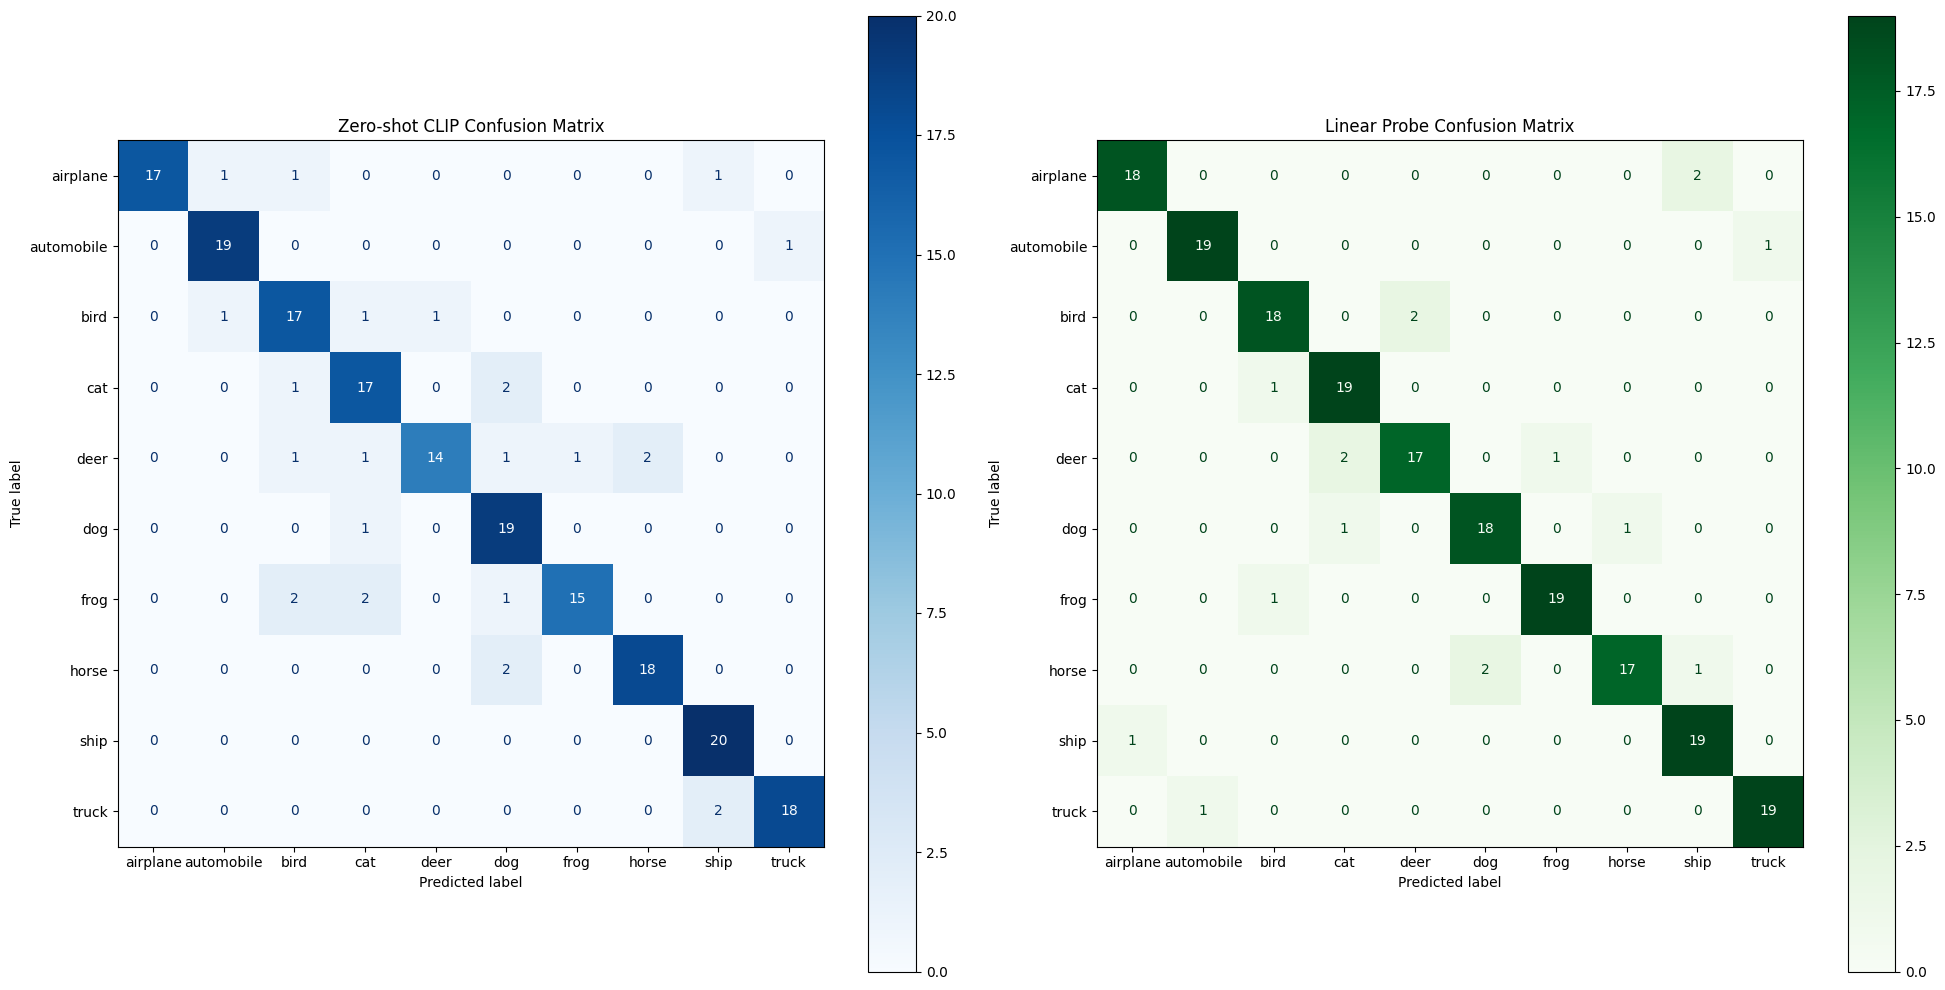

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm_zs = confusion_matrix(y_test, zs_preds)
cm_lp = confusion_matrix(y_test, lp_preds)

fig, axes = plt.subplots(1, 2, figsize=(20, 10))

# Zero-shot CM
disp1 = ConfusionMatrixDisplay(cm_zs, display_labels=class_names)
disp1.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Zero-shot CLIP Confusion Matrix")

# Linear probe CM
disp2 = ConfusionMatrixDisplay(cm_lp, display_labels=class_names)
disp2.plot(ax=axes[1], cmap="Greens", values_format="d")
axes[1].set_title("Linear Probe Confusion Matrix")

plt.tight_layout()
plt.show()


In [ ]:
zs_per_class = cm_zs.diagonal() / cm_zs.sum(axis=1)
lp_per_class = cm_lp.diagonal() / cm_lp.sum(axis=1)

comparison_df = pd.DataFrame({
    "Class": class_names,
    "Zero-shot Acc": zs_per_class,
    "Linear Probe Acc": lp_per_class,
    "Improvement": lp_per_class - zs_per_class
})

print("\n=== PER-CLASS COMPARISON ===")
print(comparison_df.to_string(index=False))



=== PER-CLASS COMPARISON ===
     Class  Zero-shot Acc  Linear Probe Acc  Improvement
  airplane           0.85              0.90         0.05
automobile           0.95              0.95         0.00
      bird           0.85              0.90         0.05
       cat           0.85              0.95         0.10
      deer           0.70              0.85         0.15
       dog           0.95              0.90        -0.05
      frog           0.75              0.95         0.20
     horse           0.90              0.85        -0.05
      ship           1.00              0.95        -0.05
     truck           0.90              0.95         0.05


In [ ]:
from sklearn.metrics import classification_report

print("\n=== PER-CLASS PERFORMANCE ===")
print(classification_report(y_test, clf.predict(X_test), target_names=class_names))



=== PER-CLASS PERFORMANCE ===
              precision    recall  f1-score   support

    airplane       0.95      0.90      0.92        20
  automobile       0.95      0.95      0.95        20
        bird       0.90      0.90      0.90        20
         cat       0.86      0.95      0.90        20
        deer       0.89      0.85      0.87        20
         dog       0.90      0.90      0.90        20
        frog       0.95      0.95      0.95        20
       horse       0.94      0.85      0.89        20
        ship       0.86      0.95      0.90        20
       truck       0.95      0.95      0.95        20

    accuracy                           0.92       200
   macro avg       0.92      0.91      0.91       200
weighted avg       0.92      0.92      0.91       200



In [ ]:
print("\n=== LINEAR PROBE VS ZERO-SHOT COMPARISON ===")

print(f"Zero-shot CLIP accuracy:   {acc:.3f}")
print(f"Linear Probe accuracy:     {lp_acc:.3f}")

improvement = lp_acc - acc
print(f"Improvement (LP - Zero-Shot): {improvement:.3f}")



=== LINEAR PROBE VS ZERO-SHOT COMPARISON ===
Zero-shot CLIP accuracy:   0.872
Linear Probe accuracy:     0.915
Improvement (LP - Zero-Shot): 0.043


In [ ]:
def image_to_text(image, prompt_text):
    if image is None:
        return "Upload an image first.", None, None

    prompts = [p.strip() for p in prompt_text.split(",") if p.strip()]
    if len(prompts) == 0:
        return "Enter at least one prompt.", None, None

    # Encode image
    inp = processor(images=image, return_tensors="pt").to(device)
    with torch.no_grad():
        img_emb = model.get_image_features(**inp)
        img_emb = img_emb / img_emb.norm(dim=-1, keepdim=True)

    # Encode text
    txt_emb = encode_texts_demo(prompts, model, processor, device)

    # Similarity
    sim = (img_emb @ txt_emb.T).cpu().numpy().flatten()
    table = "\n".join([f"{prompts[i]:40s} → {sim[i]:.4f}" for i in range(len(prompts))])

    best_idx = int(np.argmax(sim))
    return table, prompts[best_idx], float(sim[best_idx])


In [ ]:
def text_to_image(prompt):
    if not prompt.strip():
        return "Enter a prompt.", None

    txt_emb = encode_texts_demo(prompt, model, processor, device)[0]

    sim = (gallery_embeddings @ txt_emb).cpu().numpy()
    best_idx = int(np.argmax(sim))

    best_label = class_names[gallery_labels[best_idx]]
    best_img = gallery_images[best_idx]

    return best_label, best_img


In [ ]:
def cifar10_top5(image):
    if image is None:
        return "Upload an image first."

    prompts = [f"a photo of a {c}" for c in class_names]
    txt_emb = encode_texts(prompts, model, processor, device)

    inp = processor(images=image, return_tensors="pt").to(device)
    with torch.no_grad():
        img_emb = model.get_image_features(**inp)
        img_emb = img_emb / img_emb.norm(dim=-1, keepdim=True)

    sim = (img_emb @ txt_emb.T).cpu().numpy().flatten()
    top5 = np.argsort(sim)[::-1][:5]

    return "\n".join([f"{class_names[i]} → {sim[i]:.4f}" for i in top5])


In [ ]:
def ensemble_test(image):
    if image is None:
        return "Upload an image first."

    inp = processor(images=image, return_tensors="pt").to(device)
    with torch.no_grad():
        img_emb = model.get_image_features(**inp)
        img_emb = img_emb / img_emb.norm(dim=-1, keepdim=True)

    results = {}

    for name, templates in ensembles.items():
        class_emb = []
        for c in class_names:
            prompts = [t.format(label=c) for t in templates]
            emb = encode_texts(prompts, model, processor, device)
            class_emb.append(emb.mean(dim=0))

        class_emb = torch.stack(class_emb)
        sim = (img_emb @ class_emb.T).cpu().numpy().flatten()

        best_idx = int(np.argmax(sim))
        results[name] = f"{class_names[best_idx]} → {sim[best_idx]:.4f}"

    return "\n".join([f"{k}: {v}" for k, v in results.items()])


In [ ]:
with gr.Blocks() as demo:

    gr.Markdown("# 🎯 CLIP Interactive Demo (Image ↔ Text Search + CIFAR-10 + Ensembles)")
    gr.Markdown("Upload an image or type a prompt to explore CLIP capabilities.")

    with gr.Row():
        img_in = gr.Image(type="pil", label="Upload Image")
        txt_in = gr.Textbox(label="Enter prompts (comma-separated)", placeholder="e.g., a truck, a dog")

    btn1 = gr.Button("🔍 Image → Text Similarity")
    btn2 = gr.Button("🔎 Text → Image (Best CIFAR Match)")
    btn3 = gr.Button("📊 Image → CIFAR-10 Zero-Shot Top-5")
    btn4 = gr.Button("🎭 Ensemble A/B/C Evaluation")

    out_sim = gr.Textbox(label="Similarity Scores")
    out_best_prompt = gr.Textbox(label="Best Matching Prompt")
    out_score = gr.Number(label="Similarity Score")

    out_label = gr.Textbox(label="Best Matching CIFAR-10 Class")
    out_img = gr.Image(label="Retrieved CIFAR Image")

    out_cifar = gr.Textbox(label="CIFAR-10 Top-5 Predictions")
    out_ensemble = gr.Textbox(label="Ensemble Results")

    btn1.click(image_to_text, inputs=[img_in, txt_in], outputs=[out_sim, out_best_prompt, out_score])
    btn2.click(text_to_image, inputs=txt_in, outputs=[out_label, out_img])
    btn3.click(cifar10_top5, inputs=img_in, outputs=out_cifar)
    btn4.click(ensemble_test, inputs=img_in, outputs=out_ensemble)

demo.launch()


It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://42f8a1ed59130df603.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)



   FULL EVALUATION PIPELINE

Embeddings ready for: Canonical + Ensembles A, B, C.

=== Canonical RESULTS ===
Accuracy:       0.8720
Macro F1:       0.8714
Weighted F1:    0.8714
Top-1 Accuracy: 0.8720
Top-5 Accuracy: 0.9930
Top-6 Accuracy: 0.9980

=== Ensemble A (Basic) RESULTS ===
Accuracy:       0.8710
Macro F1:       0.8700
Weighted F1:    0.8700
Top-1 Accuracy: 0.8710
Top-5 Accuracy: 0.9950
Top-6 Accuracy: 0.9970

=== Ensemble B (Bad) RESULTS ===
Accuracy:       0.8750
Macro F1:       0.8749
Weighted F1:    0.8749
Top-1 Accuracy: 0.8750
Top-5 Accuracy: 0.9950
Top-6 Accuracy: 0.9970

=== Ensemble C (Medium) RESULTS ===
Accuracy:       0.8620
Macro F1:       0.8613
Weighted F1:    0.8613
Top-1 Accuracy: 0.8620
Top-5 Accuracy: 0.9930
Top-6 Accuracy: 0.9970

  CONFUSION MATRICES


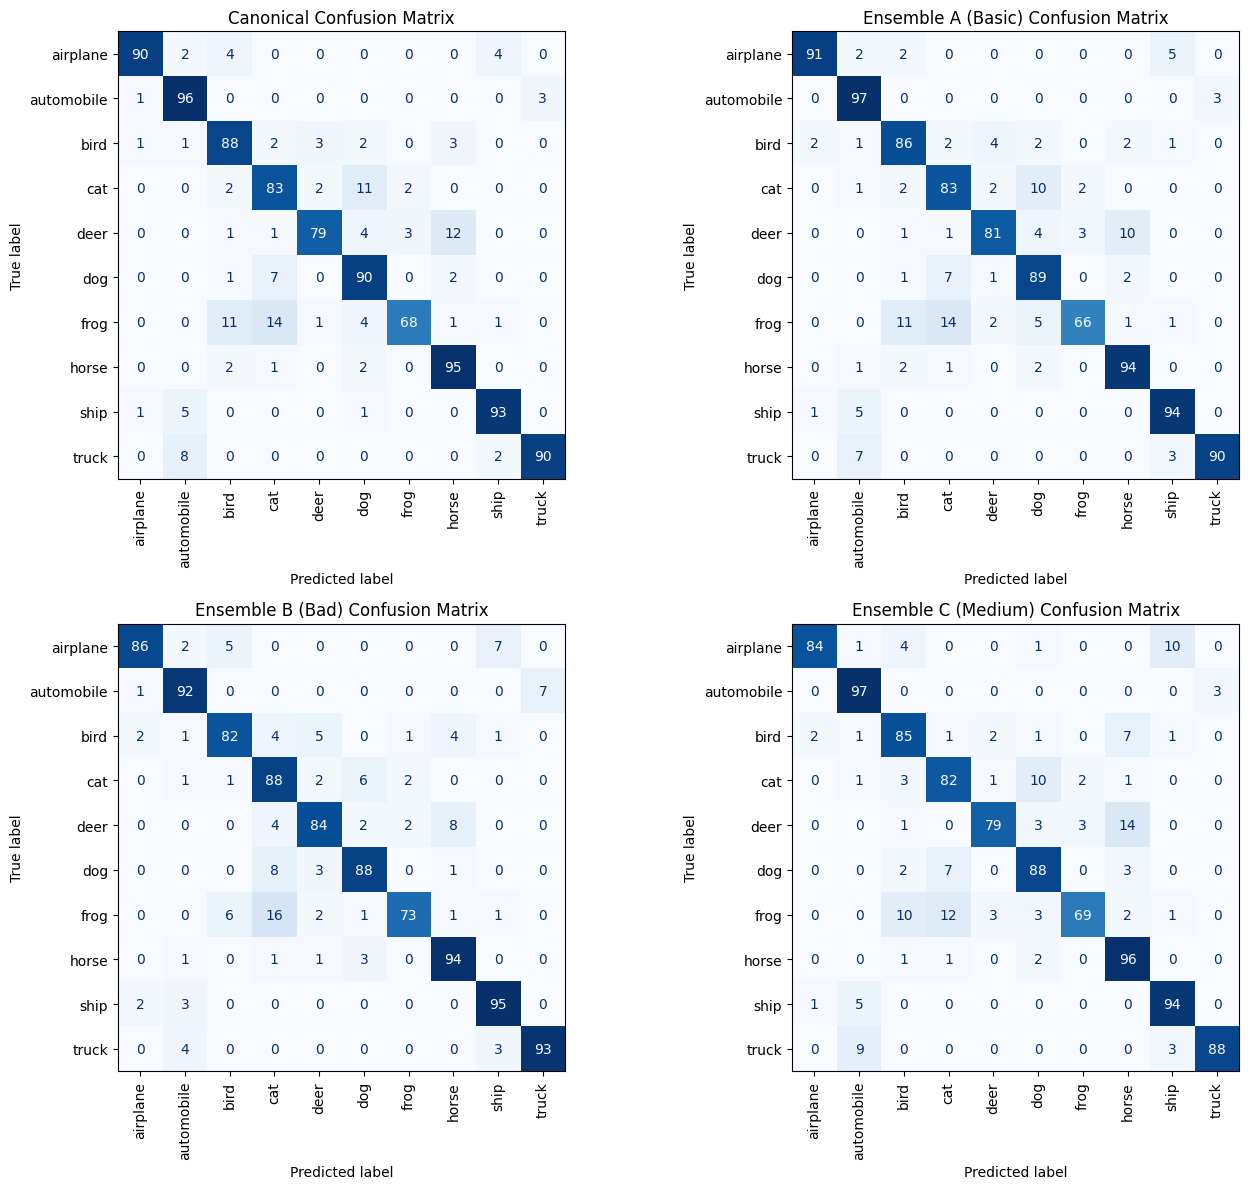


  PER-CLASS F1 SCORES


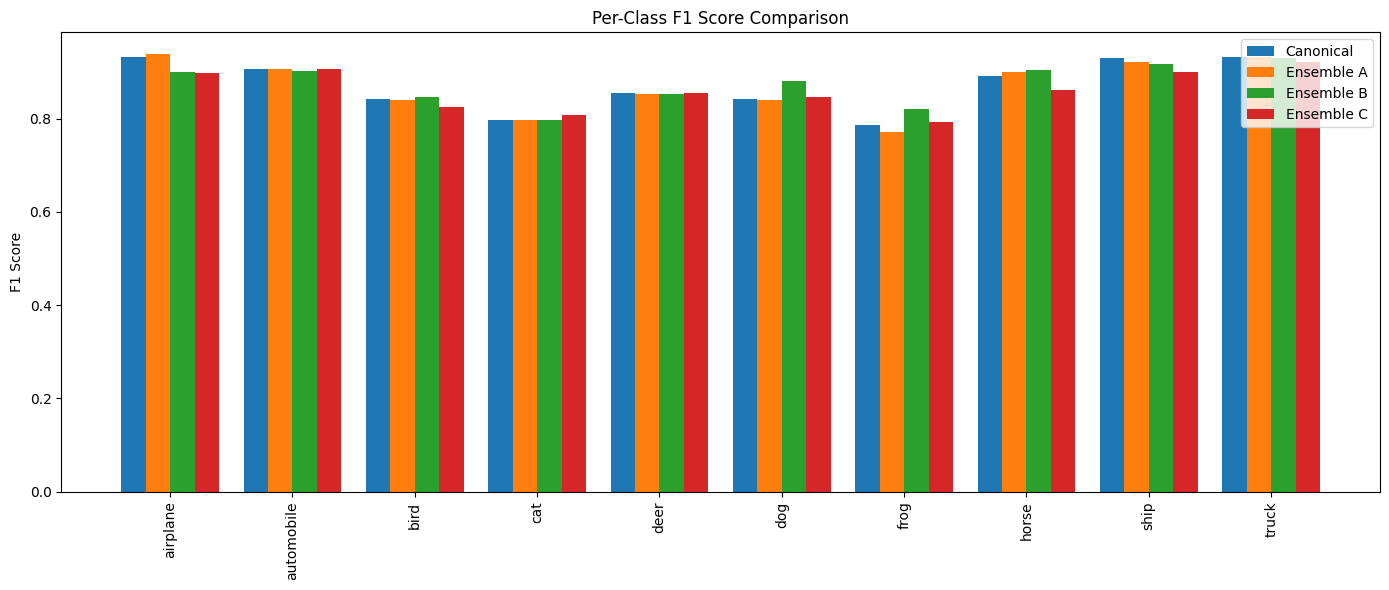

In [ ]:
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

print("\n==============================")
print("   FULL EVALUATION PIPELINE")
print("==============================\n")

# ------------------------------
# 1. Build Canonical Class Embeddings
# ------------------------------
canonical_prompts = [f"a photo of a {c}" for c in class_names]
canonical_embs = encode_texts(canonical_prompts, model, processor, device)  # shape (10,512)

# ------------------------------
# 2. Build Ensemble Class Embeddings (A, B, C)
# ------------------------------
ensemble_embeddings = {}

for name, templates in ensembles.items():
    class_embs = []
    for c in class_names:
        prompts = [t.format(label=c) for t in templates]
        emb = encode_texts(prompts, model, processor, device).mean(dim=0)  # avg text embedding
        class_embs.append(emb)
    ensemble_embeddings[name] = torch.stack(class_embs)   # shape (10,512)

print("Embeddings ready for: Canonical + Ensembles A, B, C.")

# ------------------------------
# Helper: top-k predictions
# ------------------------------
def get_predictions(image_embs, class_embs):
    sims = image_embs @ class_embs.T     # (N,10)
    preds = sims.argmax(dim=1).cpu().numpy()
    return sims, preds

def top_k_accuracy(image_embs, class_embs, labels, k):
    sims = image_embs @ class_embs.T
    topk = sims.topk(k, dim=1).indices.cpu().numpy()
    correct = [1 if labels[i] in topk[i] else 0 for i in range(len(labels))]
    return np.mean(correct)

# ------------------------------
# Evaluate all models
# ------------------------------
results = {}

def evaluate_model(model_name, class_embs):
    sims, preds = get_predictions(gallery_embeddings, class_embs)

    acc = accuracy_score(gallery_labels, preds)
    f1_macro = f1_score(gallery_labels, preds, average="macro")
    f1_weighted = f1_score(gallery_labels, preds, average="weighted")

    top1 = top_k_accuracy(gallery_embeddings, class_embs, gallery_labels, 1)
    top5 = top_k_accuracy(gallery_embeddings, class_embs, gallery_labels, 5)
    top6 = top_k_accuracy(gallery_embeddings, class_embs, gallery_labels, 6)

    results[model_name] = {
        "preds": preds,
        "acc": acc,
        "macro_f1": f1_macro,
        "weighted_f1": f1_weighted,
        "top1": top1,
        "top5": top5,
        "top6": top6,
    }

    print(f"\n=== {model_name} RESULTS ===")
    print(f"Accuracy:       {acc:.4f}")
    print(f"Macro F1:       {f1_macro:.4f}")
    print(f"Weighted F1:    {f1_weighted:.4f}")
    print(f"Top-1 Accuracy: {top1:.4f}")
    print(f"Top-5 Accuracy: {top5:.4f}")
    print(f"Top-6 Accuracy: {top6:.4f}")

# Evaluate canonical
evaluate_model("Canonical", canonical_embs)

# Evaluate ensembles A, B, C
for name in ensembles:
    evaluate_model(name, ensemble_embeddings[name])

# ------------------------------
# CONFUSION MATRICES
# ------------------------------
print("\n==============================")
print("  CONFUSION MATRICES")
print("==============================")

fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes = axes.flatten()

models = ["Canonical"] + list(ensembles.keys())

for ax, model_name in zip(axes, models):
    cm = confusion_matrix(gallery_labels, results[model_name]["preds"])
    ConfusionMatrixDisplay(cm, display_labels=class_names).plot(
        ax=ax, cmap="Blues", values_format='d', colorbar=False
    )
    ax.set_title(f"{model_name} Confusion Matrix")
    ax.tick_params(axis='x', rotation=90)

plt.tight_layout()
plt.show()

# ------------------------------
# PER-CLASS F1 BAR CHARTS
# ------------------------------

print("\n==============================")
print("  PER-CLASS F1 SCORES")
print("==============================")

fig, ax = plt.subplots(figsize=(14, 6))

x = np.arange(len(class_names))
width = 0.2

f1_can = f1_score(gallery_labels, results["Canonical"]["preds"], average=None)
f1_A = f1_score(gallery_labels, results["Ensemble A (Basic)"]["preds"], average=None)
f1_B = f1_score(gallery_labels, results["Ensemble B (Bad)"]["preds"], average=None)
f1_C = f1_score(gallery_labels, results["Ensemble C (Medium)"]["preds"], average=None)

ax.bar(x - 1.5*width, f1_can, width, label="Canonical")
ax.bar(x - 0.5*width, f1_A, width, label="Ensemble A")
ax.bar(x + 0.5*width, f1_B, width, label="Ensemble B")
ax.bar(x + 1.5*width, f1_C, width, label="Ensemble C")

ax.set_xticks(x)
ax.set_xticklabels(class_names, rotation=90)
ax.set_ylabel("F1 Score")
ax.set_title("Per-Class F1 Score Comparison")
ax.legend()
plt.tight_layout()
plt.show()



  ACCURACY COMPARISON PLOTS


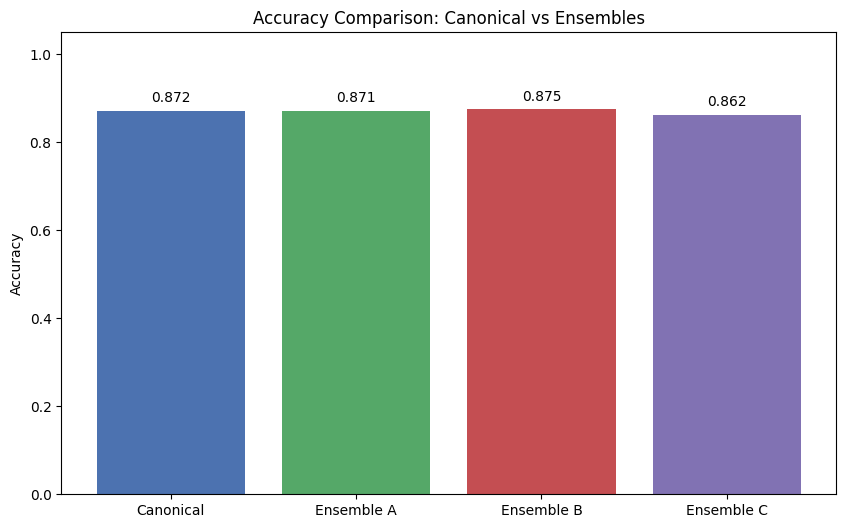

In [ ]:
# ------------------------------
# ACCURACY COMPARISON PLOTS
# ------------------------------

print("\n==============================")
print("  ACCURACY COMPARISON PLOTS")
print("==============================")

# Extract accuracy for Canonical + Ensembles
acc_canonical = results["Canonical"]["acc"]
acc_A = results["Ensemble A (Basic)"]["acc"]
acc_B = results["Ensemble B (Bad)"]["acc"]
acc_C = results["Ensemble C (Medium)"]["acc"]

accuracy_values = [acc_canonical, acc_A, acc_B, acc_C]
labels = ["Canonical", "Ensemble A", "Ensemble B", "Ensemble C"]

plt.figure(figsize=(10, 6))
plt.bar(labels, accuracy_values, color=["#4c72b0", "#55a868", "#c44e52", "#8172b3"])
plt.title("Accuracy Comparison: Canonical vs Ensembles")
plt.ylabel("Accuracy")
plt.ylim(0, 1.05)
for i, v in enumerate(accuracy_values):
    plt.text(i, v + 0.02, f"{v:.3f}", ha='center')
plt.show()



  ZERO-SHOT vs LINEAR PROBE ACCURACY


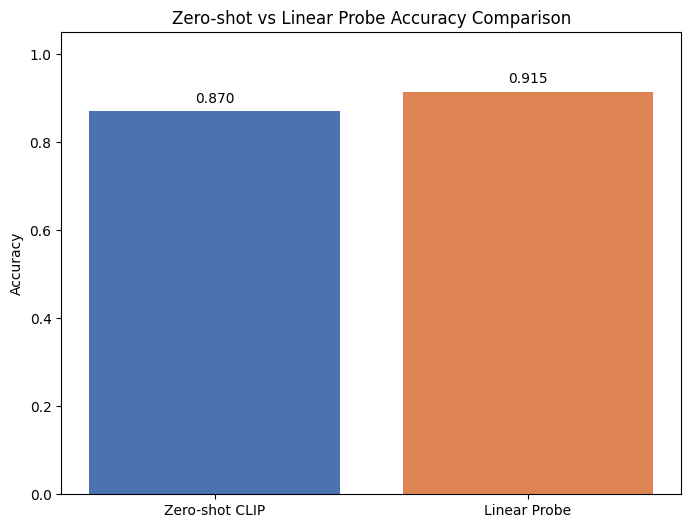

In [ ]:
# ------------------------------
# ZERO-SHOT vs LINEAR PROBE ACCURACY
# ------------------------------

print("\n==============================")
print("  ZERO-SHOT vs LINEAR PROBE ACCURACY")
print("==============================")

acc_values = [zs_acc, lp_acc]
labels = ["Zero-shot CLIP", "Linear Probe"]

plt.figure(figsize=(8, 6))
plt.bar(labels, acc_values, color=["#4c72b0", "#dd8452"])
plt.title("Zero-shot vs Linear Probe Accuracy Comparison")
plt.ylabel("Accuracy")
plt.ylim(0, 1.05)
for i, v in enumerate(acc_values):
    plt.text(i, v + 0.02, f"{v:.3f}", ha='center')
plt.show()



  FULL MODEL PERFORMANCE COMPARISON


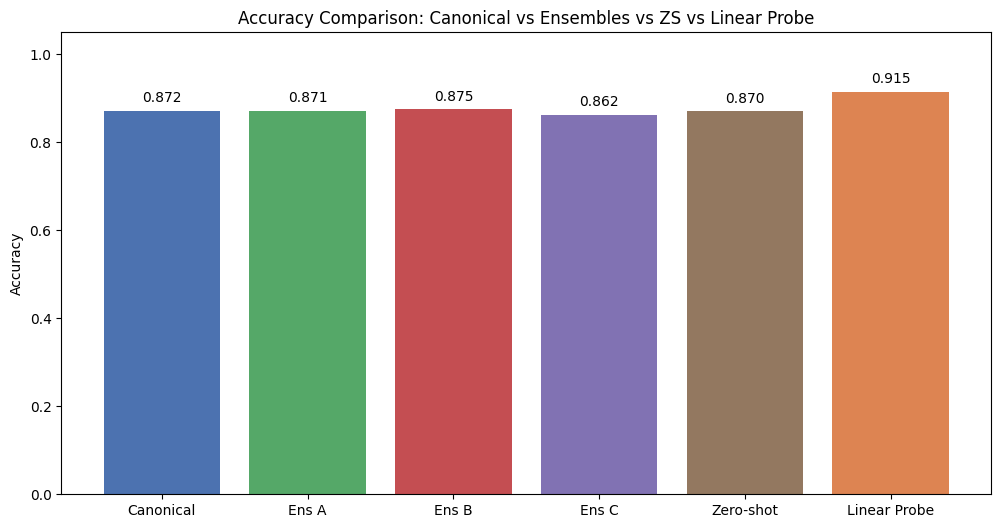

In [ ]:
# ------------------------------
# FULL MODEL COMPARISON
# ------------------------------

print("\n==============================")
print("  FULL MODEL PERFORMANCE COMPARISON")
print("==============================")

labels_full = ["Canonical", "Ens A", "Ens B", "Ens C", "Zero-shot", "Linear Probe"]
acc_full = [
    acc_canonical,
    acc_A,
    acc_B,
    acc_C,
    zs_acc,
    lp_acc
]

plt.figure(figsize=(12, 6))
plt.bar(labels_full, acc_full,
        color=["#4c72b0", "#55a868", "#c44e52", "#8172b3", "#937860", "#dd8452"])
plt.title("Accuracy Comparison: Canonical vs Ensembles vs ZS vs Linear Probe")
plt.ylabel("Accuracy")
plt.ylim(0, 1.05)
for i, v in enumerate(acc_full):
    plt.text(i, v + 0.02, f"{v:.3f}", ha='center')
plt.show()
